In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
data = {
    "Purchased": ["Yes", "Yes", "No", "No"],
    "Ad_Clicked": ["Yes", "No", "Yes", "No"],
    "Customers": [30, 20, 10, 40]
}
df = pd.DataFrame(data)
df

,Purchased,Ad_Clicked,Customers
0,Yes,Yes,30
1,Yes,No,20
2,No,Yes,10
3,No,No,40


In [4]:
total_customers = df["Customers"].sum()
total_customers

np.int64(100)

In [6]:
prob_purchase = (
    df.loc[df["Purchased"] == "Yes", "Customers"].sum()
    / total_customers
)
prob_purchase

np.float64(0.5)

In [7]:
prob_both = (
    df.loc[
        (df["Purchased"] == "Yes") & (df["Ad_Clicked"] == "Yes"),
        "Customers"
    ].sum()
    / total_customers
)
prob_both

np.float64(0.3)

In [8]:
total_clicked = df.loc[
    df["Ad_Clicked"] == "Yes", "Customers"
].sum()

prob_conditional = (
    df.loc[
        (df["Purchased"] == "Yes") & (df["Ad_Clicked"] == "Yes"),
        "Customers"
    ].sum()
    / total_clicked
)
total_clicked

np.int64(40)

In [9]:
print(f"P(A) = {prob_purchase:.2f}")
print(f"P(A ∩ B) = {prob_both:.2f}")
print(f"P(A | B) = {prob_conditional:.2f}")

P(A) = 0.50
P(A ∩ B) = 0.30
P(A | B) = 0.75


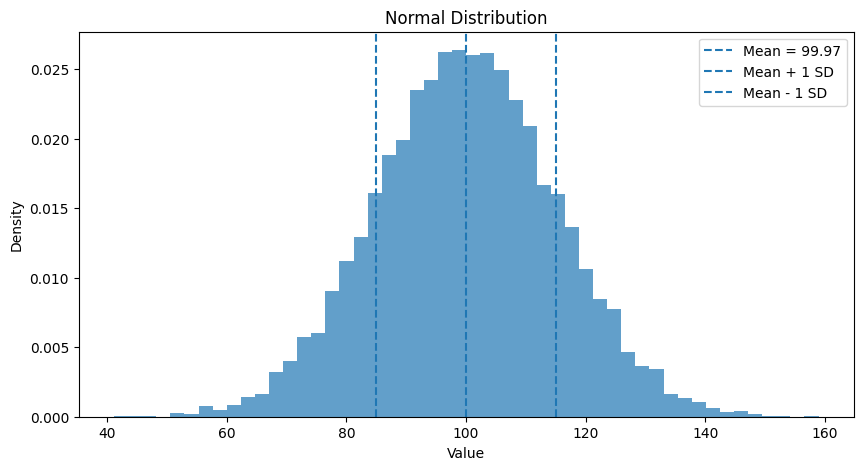

Mean: 99.97
Standard Deviation: 15.05


In [11]:
np.random.seed(42)

data = np.random.normal(loc=100, scale=15, size=10000)

# Calculate mean and standard deviation
mean = np.mean(data)
std = np.std(data)

# Plot the distribution
plt.figure(figsize=(10, 5))
plt.hist(data, bins=50, density=True, alpha=0.7)

plt.axvline(mean, linestyle="--", label=f"Mean = {mean:.2f}")
plt.axvline(mean + std, linestyle="--", label="Mean + 1 SD")
plt.axvline(mean - std, linestyle="--", label="Mean - 1 SD")

plt.title("Normal Distribution")
plt.xlabel("Value")
plt.ylabel("Density")
plt.legend()
plt.show()

print(f"Mean: {mean:.2f}")
print(f"Standard Deviation: {std:.2f}")

In [12]:
within_1_std = np.mean(
    (data >= mean - std) & (data <= mean + std)
) * 100
within_2_std = np.mean(
    (data >= mean - 2 * std) & (data <= mean + 2 * std)
) * 100
within_3_std = np.mean(
    (data >= mean - 3 * std) & (data <= mean + 3 * std)
) * 100
print(f"Within 1 standard deviation: {within_1_std:.2f}%")
print(f"Within 2 standard deviations: {within_2_std:.2f}%")
print(f"Within 3 standard deviations: {within_3_std:.2f}%")

Within 1 standard deviation: 68.38%
Within 2 standard deviations: 95.38%
Within 3 standard deviations: 99.73%


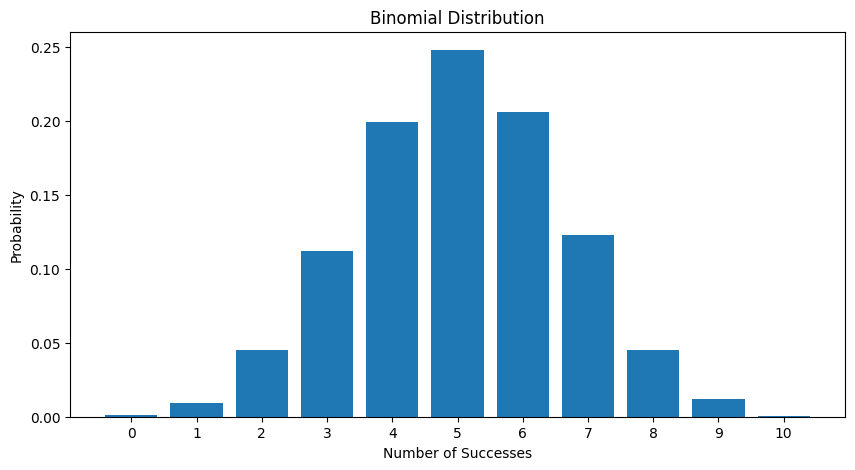

Mean: 5.0393
Standard Deviation: 1.5905205154288329


In [13]:
n = 10
p = 0.5
simulations = 10000
results = np.random.binomial(n, p, simulations)
plt.figure(figsize=(10, 5))
values, counts = np.unique(results, return_counts=True)
plt.bar(values, counts / simulations)
plt.title("Binomial Distribution")
plt.xlabel("Number of Successes")
plt.ylabel("Probability")
plt.xticks(range(n + 1))
plt.show()
print("Mean:", np.mean(results))
print("Standard Deviation:", np.std(results))

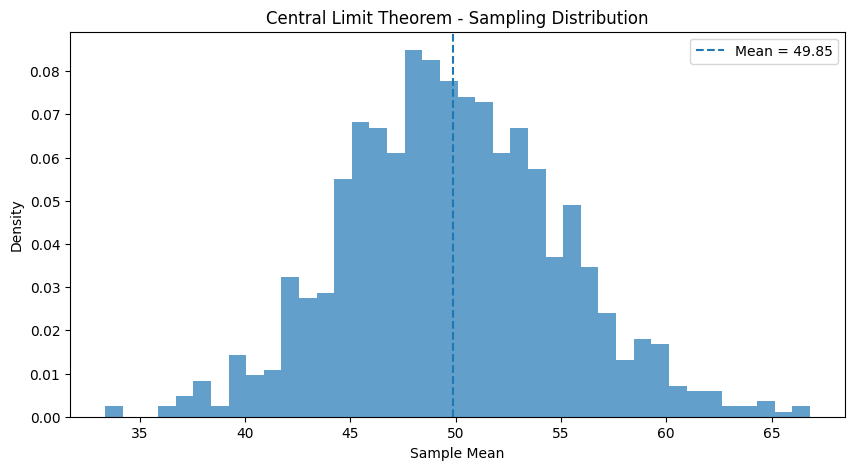

Population Mean: 49.93
Mean of Sample Means: 49.85
Standard Deviation of Sample Means: 5.15


In [ ]:
population = np.random.uniform(0, 100, 100000)
sample_means = []
for i in range(1000):
    sample = np.random.choice(population, size=30)
    sample_means.append(np.mean(sample))
sample_means = np.array(sample_means)
plt.figure(figsize=(10, 5))
plt.hist(sample_means, bins=40, density=True, alpha=0.7)
plt.title("Central Limit Theorem - Sampling Distribution")
plt.xlabel("Sample Mean")
plt.ylabel("Density")
plt.axvline(
    np.mean(sample_means),
    linestyle="--",
    label=f"Mean = {np.mean(sample_means):.2f}"
)
plt.legend()
plt.show()
print("Population Mean:", round(np.mean(population), 2))
print("Mean of Sample Means:", round(np.mean(sample_means), 2))
print("Standard Deviation of Sample Means:", round(np.std(sample_means), 2))